# Identification des utilisateurs de Copilote

**MOD 7.2 – Introduction à la science des données – BE**

Groupe : Achraf BITAR.

**Objectif.** À partir des traces d'utilisation du logiciel Copilote (Infologic), retrouver quel utilisateur a réalisé une session. C'est une tâche de **classification supervisée** : chaque session est un **individu** décrit par des **variables explicatives** $X$, et sa **classe** $Z$ est l'utilisateur.

## 1. Chargement des données

Nous commençons par importer les bibliothèques.

In [14]:
import os
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)   # pour sauvegarder les graphiques du rapport

Chaque ligne d'un fichier est une **session** : utilisateur, navigateur, puis les actions, séparées par des virgules. La fonction `read_ds` du notebook d'indications crée un tableau de 14 470 colonnes presque vides. 
Donc on lit le fichier **ligne par ligne** (`readlines`) et on garde, pour chaque session, la **liste de ses actions** dans une seule colonne.

In [ ]:
def lire_fichier(nom):
    """Lit data/non.csv ligne par ligne."""
    sessions = []
    with open(f"data/{nom}.csv", encoding="utf-8") as f:
        for ligne in f.readlines():
            morceaux = ligne.rstrip("\n").split(",")
            if nom == "train":
                sessions.append({"util": morceaux[0], "navigateur": morceaux[1], "actions": morceaux[2:]})
            else:
                sessions.append({"navigateur": morceaux[0], "actions": morceaux[1:]})
    return pd.DataFrame(sessions)


train = lire_fichier("train")
test = lire_fichier("test")
print("train :", train.shape, "| test :", test.shape)
train.head()

train : (3279, 3) | test : (324, 2)


,util,navigateur,actions
0,nuh,Firefox,[Création d'un écran(infologic.core.accueil.Ac...
1,muz,Google Chrome,[Création d'un écran(infologic.core.gui.contro...
2,zrx,Microsoft Edge,[Affichage d'une dialogue(infologic.core.gui.c...
3,pou,Firefox,[Création d'un écran(infologic.core.gui.contro...
4,ald,Google Chrome,[Affichage d'une dialogue(infologic.acti.modul...


In [16]:
train.loc[0, "actions"][:15]

["Création d'un écran(infologic.core.accueil.AccueilController)",
 "Affichage d'une dialogue",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Affichage d'une dialogue",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)",
 't5',
 "Exécution d'un bouton(MAINT)",
 "Affichage d'une dialogue",
 "Fermeture d'une dialogue",
 'Double-clic',
 "Exécution d'un bouton",
 "Lancement d'une stat(infologic.core.gui.controllers.nested.homeview.InputFormHomeView)"]

## 2. Statistiques simples

### 2.1 Les navigateurs

In [27]:
pd.DataFrame({"train": train["navigateur"].value_counts(),
              "test": test["navigateur"].value_counts()})

,train,test
navigateur,,
Firefox,1466,147
Google Chrome,1339,133
Microsoft Edge,451,42
Opera,23,2


In [28]:
navigateur_par_utilisateur = pd.crosstab(train["util"], train["navigateur"])
nb_navigateurs = (navigateur_par_utilisateur > 0).sum(axis=1)
print("Utilisateurs ayant utilisé plus d'un navigateur :", (nb_navigateurs > 1).sum())
print("Nombre d'utilisateurs par navigateur :")
print((navigateur_par_utilisateur > 0).sum())

Utilisateurs ayant utilisé plus d'un navigateur : 0
Nombre d'utilisateurs par navigateur :
navigateur
Firefox           114
Google Chrome      93
Microsoft Edge     39
Opera               1
dtype: int64


**Analyse.** Le mode est Firefox ; Opera est très rare. Surtout, chaque utilisateur utilise toujours le même navigateur (114 sous Firefox, 93 sous Chrome, 39 sous Edge, un seul sous Opera) : le navigateur élimine d'office beaucoup de classes // c'est une variable explicative à garder.

### 2.2 La classe à prédire : l'utilisateur

Nombre d utilisateurs : 247
count    247.0
mean      13.3
std        8.9
min        4.0
25%        7.0
50%       12.0
75%       16.0
max       75.0
Name: count, dtype: float64


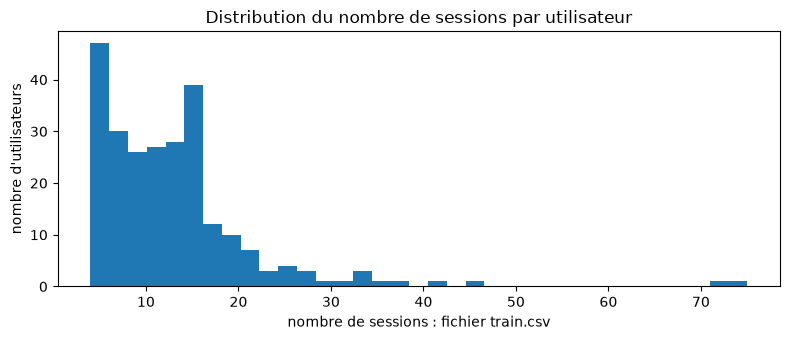

In [31]:
sessions_par_utilisateur = train["util"].value_counts()
print("Nombre d utilisateurs :", sessions_par_utilisateur.size)
print(sessions_par_utilisateur.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(sessions_par_utilisateur, bins=35)
ax.set_xlabel("nombre de sessions : fichier train.csv")
ax.set_ylabel("nombre d'utilisateurs")
ax.set_title("Distribution du nombre de sessions par utilisateur")
plt.tight_layout()
plt.savefig("figures/sessions_par_utilisateur.png", dpi=150)
plt.show()

*Analyse :* La distrubution du nombre de sessions par utilisateur est déséquilibrée donc le taux de bon classement seule n'est pas suffisant, on utilise aussi la F mesure macro

### 2.3 Longueur et durée des sessions

Un marqueur `tXX` indique le temps écoulé depuis le début de la session (un toutes les 5 secondes).

In [35]:
def est_marqueur_temps(valeur):
    return re.fullmatch(r"t\d+", valeur) is not None # regex pattern pour detection du format txx


def resume_session(actions):
    temps = [int(a[1:]) for a in actions if est_marqueur_temps(a)]
    nb_actions = len(actions) - len(temps)
    return pd.Series({"nb_actions": nb_actions, "duree_s": max(temps) if temps else 0})

print(train.head())
print(test.head())
resume_train = train["actions"].apply(resume_session)
resume_test = test["actions"].apply(resume_session)
pd.concat({"train": resume_train.describe(), "test": resume_test.describe()}, axis=1).round(1)

  util      navigateur                                            actions
0  nuh         Firefox  [Création d'un écran(infologic.core.accueil.Ac...
1  muz   Google Chrome  [Création d'un écran(infologic.core.gui.contro...
2  zrx  Microsoft Edge  [Affichage d'une dialogue(infologic.core.gui.c...
3  pou         Firefox  [Création d'un écran(infologic.core.gui.contro...
4  ald   Google Chrome  [Affichage d'une dialogue(infologic.acti.modul...
       navigateur                                            actions
0  Microsoft Edge  [Saisie dans un champ, t5, Saisie dans un cham...
1         Firefox  [Création d'un écran(infologic.core.accueil.Ac...
2   Google Chrome  [Clic long, Création d'un écran(infologic.core...
3   Google Chrome  [Sélection d’un onglet(infologic.core.gui.cont...
4         Firefox  [Affichage d'une dialogue(infologic.acti.modul...


train                test        
      nb_actions  duree_s nb_actions duree_s
count     3279.0   3279.0      324.0   324.0
mean       692.4    751.5      662.3   739.9
std       1005.9   1006.3      811.5   920.9
min          0.0      5.0        9.0    20.0
25%        153.0    185.0      161.5   190.0
50%        340.0    395.0      365.0   407.5
75%        818.5    945.0      819.2   935.0
max      11977.0  11790.0     6203.0  7110.0

**Analyse.** La session médiane contient 340 actions et dure 395 s, mais la dispersion est énorme. La moyenne (692 actions) est deux fois plus grande que la médiane : la distribution est très asymétrique, avec quelques sessions très longues qui tirent la moyenne vers le haut.

Comparer des comptes bruts n'aurait donc pas de sens.

Le test ressemble au train (médianes et quartiles proches). On remarque aussi des sessions presque vides (minimum à 0 action) : on les étudiera à l'étape suivante, avec les **données aberrantes**.

## 3. Nettoyage : données aberrantes

Les **données aberrantes** (*outliers*) sont des données atypiques qui s'écartent fortement de la tendance centrale. Pour les détecter, on combine deux approches vues en cours :
- une **méthode à base de seuil** : la règle de l'**écart interquartile** (IQR). Une valeur est suspecte si elle est en dehors de $[Q_1 - 1{,}5 \times IQR \; ; \; Q_3 + 1{,}5 \times IQR]$ ;
- une **observation visuelle** avec une boîte à moustaches.

Comme le nombre d’actions s’étale sur plusieurs ordres de grandeur, avec une longue queue à droite. on applique la règle sur $\log(1 + \text{nombre d'actions})$ afin de rendre la distrubution plus symétrique et le +1 pour eviter des valeurs de log indétérminer.

In [36]:
log_nb = np.log1p(resume_train["nb_actions"])
q1, q3 = log_nb.quantile([0.25, 0.75])
iqr = q3 - q1
borne_basse, borne_haute = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Bornes de la règle IQR : de {np.expm1(borne_basse):.1f} à {np.expm1(borne_haute):.0f} actions")

aberrantes_basses = log_nb < borne_basse
aberrantes_hautes = log_nb > borne_haute
print("\nSessions sous la borne basse :")
print(train.assign(nb_actions=resume_train["nb_actions"]).loc[aberrantes_basses, ["util", "navigateur", "nb_actions"]])
print("\nSessions au-dessus de la borne haute :")
print(train.assign(nb_actions=resume_train["nb_actions"], duree_s=resume_train["duree_s"]).loc[aberrantes_hautes, ["util", "nb_actions", "duree_s"]])

# Sur les comptes bruts (sans log), la règle signalerait beaucoup trop de sessions
q1_brut, q3_brut = resume_train["nb_actions"].quantile([0.25, 0.75])
print("\nRègle IQR sur les comptes bruts :", (resume_train["nb_actions"] > q3_brut + 1.5 * (q3_brut - q1_brut)).sum(), "sessions signalées")

Bornes de la règle IQR : de 11.5 à 10059 actions

Sessions sous la borne basse :
     util     navigateur  nb_actions
1251  fvc  Google Chrome           0
2684  zus        Firefox           2
3141  fou  Google Chrome           1

Sessions au-dessus de la borne haute :
     util  nb_actions  duree_s
84    urs       10625     8245
3082  wvy       11977    11790
3234  fxg       11505     9080

Règle IQR sur les comptes bruts : 297 sessions signalées


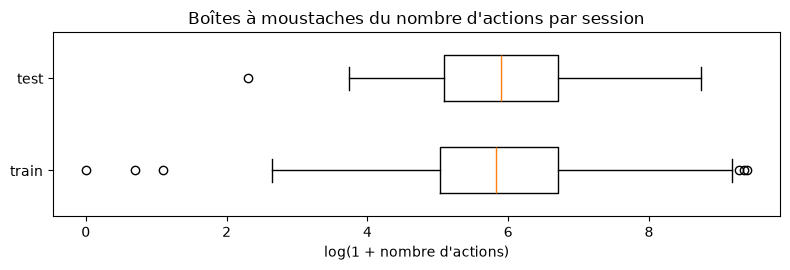

In [37]:
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.boxplot([np.log1p(resume_train["nb_actions"]), np.log1p(resume_test["nb_actions"])], orientation = 'horizontal', widths=0.5)
ax.set_yticks([1, 2], ["train", "test"])
ax.set_xlabel("log(1 + nombre d'actions)")
ax.set_title("Boîtes à moustaches du nombre d'actions par session")
plt.tight_layout()
plt.savefig("figures/donnees_aberrantes.png", dpi=150)
plt.show()

**Décision.** Sur les comptes bruts, la règle de l'écart interquartile signale 297 sessions : la distribution est trop asymétrique pour que la règle soit utile. Sur $\log(1 + \text{nombre d'actions})$, elle signale sessions

On traite différemment selon le cas, une donnée aberrante peut venir d'une erreur ou être une valeur extrême qui n'est pas une erreur :

- les **3 sessions sous la borne basse** ne contiennent presque rien (0 à 2 actions). Elles ressemblent à des sessions ouvertes par erreur : on les supprime. L'utilisateur le plus affécté garde 12 autres sessions, on ne perd donc aucune classe.
- les **3 sessions au-dessus de la borne haute** plus de 10 000 actions sont des valeurs extrêmes mais réelles : on les garde.

In [38]:
train = train[~aberrantes_basses.to_numpy()].reset_index(drop=True)
print("Taille de train après nettoyage :", train.shape)

Taille de train après nettoyage : (3276, 3)


## 4. Construction des caractéristiques

### 4.1 La variable de classe
Comme proposé, on convertit l'utilisateur en catégorie pandas : chaque utilisateur reçoit un code numérique (`cat.codes`), et on garde la liste des noms (`cat.categories`) pour revenir aux noms à la fin.

In [39]:
train["util"] = pd.Categorical(train["util"])
noms_utilisateurs = train["util"].cat.categories
y = train["util"].cat.codes.to_numpy()
print(len(noms_utilisateurs), "classes ; exemple :", list(noms_utilisateurs[:5]), "devient", list(range(5)))

247 classes ; exemple : ['aho', 'ajo', 'akx', 'ald', 'ats'] devient [0, 1, 2, 3, 4]


### 4.2 Les types d'actions
Une action brute ressemble à `Exécution d'un bouton(infologic...Controller)<DEF_03/24>$VT$1`. On utilise la fonction `filter_action` fournie pour ne garder que le **type d'action** (le texte avant `(`, `<`, `$` ou `1`).

In [24]:
def filter_action(value: str):
    for delim in ["(", "<", "$", "1"]:
        if delim in value and (low_ind := value.index(delim)):
            value = value[:low_ind]
    return value


toutes_les_actions = [a for actions in train["actions"] for a in actions if not est_marqueur_temps(a)]
print("Nombre de valeurs brutes différentes :", len(set(toutes_les_actions)))

compte_types = Counter(filter_action(a) for a in toutes_les_actions)
TYPES_ACTIONS = sorted(compte_types)
print("Nombre de types d'actions :", len(TYPES_ACTIONS))
pd.Series(compte_types).sort_values(ascending=False).to_frame("occurrences dans train")

Nombre de valeurs brutes différentes : 7087
Nombre de types d'actions : 35


,occurrences dans train
Exécution d'un bouton,510645
Saisie dans un champ,265633
Sélection d'un écran,206813
Fermeture d'une dialogue,171026
Affichage d'une dialogue,168928
Lancement d'une action générique,115283
Sélection d’un onglet,109209
Raccourci,82176
Création d'un écran,76930
Chainage,68194


Il n'y a que **35 types d'actions**, mais plus de 7 000 valeurs brutes différentes une fois qu'on tient compte de l'écran, de la configuration et de la chaîne. Les actions les plus fréquentes sont très générales (exécuter un bouton, saisir dans un champ...) : seules, elles distinguent mal les personnes. L'information intéressante est plutôt dans le contexte de l'action.

### 4.3 Écran, configuration d'écran et chaîne
On utilise les expressions : `(...)` pour l'**écran**, `<...>` pour la **configuration** de l'écran, `$...$` pour la **chaîne** de la fiche travaillée. On calcule aussi la valeur la plus fréquente de chacune dans chaque session.

In [41]:
pattern_ecran = re.compile(r"\((.*?)\)") # écran entre parenthèses
pattern_conf_ecran = re.compile(r"<(.*?)>") # configuration entre chevrons
pattern_chaine = re.compile(r"\$(.*?)\$") # chaîne entre dollars (fin du texte)


def le_plus_frequent(liste):
    return Counter(liste).most_common(1)[0][0] if liste else "aucun"  # Counter compte les occurrences, most common pour retourner la valeur la plus commune


def principaux(actions):
    texte = [a for a in actions if not est_marqueur_temps(a)] # on enlève les marqueurs de temps
    return pd.Series({
        "ecran_principal": le_plus_frequent([m for a in texte for m in pattern_ecran.findall(a)]),
        "conf_principale": le_plus_frequent([m for a in texte for m in pattern_conf_ecran.findall(a)]),
        "chaine_principale": le_plus_frequent([m for a in texte for m in pattern_chaine.findall(a)]),
    })


principaux_train = train["actions"].apply(principaux)
principaux_train.head()

,ecran_principal,conf_principale,chaine_principale
0,MAINT,DEF_03/24,JCP
1,infologic.orga.modules.OR_FICHIERTRAVAIL.Insta...,TELEM_MINIMAL,DB
2,DEMTEST,DEF_07/23,MES
3,MAINT,DEF_03/24,JCP
4,MAINT,INSTALLATEUR,GP


In [43]:
# Pour chaque utilisateur, on calcule la part de ses sessions qui ont sa valeur la plus courante
# sur les 3 variables


stabilite = (principaux_train.assign(util=train["util"])
             .groupby("util", observed=True) # on regroupe les sessions par utilisateur
             .agg(**{c: (c, lambda s: s.value_counts(normalize=True).iloc[0])
                     for c in ["ecran_principal", "conf_principale", "chaine_principale"]}))
print("Valeur moyenne sur les utilisateurs :")
stabilite.mean().round(2)

Valeur moyenne sur les utilisateurs :


ecran_principal      0.54
conf_principale      0.57
chaine_principale    0.67
dtype: float64

**Analyse.** En moyenne, l'écran principal le plus courant d'un utilisateur se retrouve dans 54 % de ses sessions (57 % pour la configuration, 67 % pour la chaîne). Ces informations sont donc assez **stables pour une même personne**. Mais ne garder que le mode perd beaucoup d'information (une session utilise souvent plusieurs écrans) : on va compter toutes les valeurs de la session.

### 4.4 Le tableau des caractéristiques

| Famille | Contenu |
|--|--|
| **A/ Simples** | nombre d'actions, durée, vitesse (actions / minute), nombre d'actions différentes, nombre d'écrans différents, navigateur |
| **B/ Proportions** | part de chacun des 35 types d'actions dans la session |
| **C/ Comptages** | occurrences de chaque action complète (C1), de chaque écran / configuration / chaîne (C2) et de chaque **paire d'actions qui se suivent** (C3) |

**Transformations** :
- famille A : variables très asymétriques, on calcule leur **logarithme** $\log(1 + x)$ ;
- navigateur : variable catégorielle à 4 modalités, on utilise le **codage disjonctif complet** (*One Hot Encoding*, `get_dummies`)
- famille C : chaque session est vue comme un « texte » dont les « mots » sont les actions. Ici on prépare seulement les listes de mots ; le **comptage** sera fait à l'étape des modèles.